In [ ]:
# Внимание!!! Важно, что бы файлы с данными и исполняемый файл находились в одной папке, 
# тогда пути к тестовым и тренировочным наборам будут содержать только имена файлов.
# 
# В пути к тренировочным и тестовым данным запрежается использовать абсалютную адресацию, 
# то есть адресацию, в которой присутствуют имена папок. Путь должен содержать только имя файла.
#
# Напоминание: под моделью машинного обучения понимаются все действия с исходными данными, 
# которые необходимо произвести, что бы сопоставить признаки целевому значению.

### Область работы 1 (библиотеки)

In [ ]:
# Данный блок в области 1 НЕ выполняется преподавателем
# 
# данный блок предназначен только для подключения необходимых библиотек
# запрещается подключать библиотеки в других блоках
#
# установка дополнительных библиотек размещается прямо здесь (обязательно закоментированы)
#
# pip install

In [124]:
import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics import confusion_matrix, precision_score, recall_score, make_scorer
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.model_selection import TunedThresholdClassifierCV
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay




### Область работы 2 (поиск  модели .... )

In [125]:
# Данный блок(и) НЕ выполняются преподавателем в области 2
# блок(и) предназначены для поиска лучшей модели 
# должен быть понятен и очевиден отбор параметров модели
# 
# Запрещается размещать данные блоки за пределами обасти 2
# Все блоки данной области должны быть выполнены
#
# ЗАПРЕЩАЕТСЯ ИСПОЛЬЗОВАТЬ ТЕСТОВЫЙ НАБОР
#
# Путь к тренировочному набору
# 

path_train = 'train.csv'  # содержит только имя файла, без имен папок !!!

In [126]:
df = pd.read_csv(path_train)
df

,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,2,18,2,6,1239,5,3,4,3,1,...,4,61,3,3,1,3,2,1,2,1
1,1,30,0,9,8072,5,2,2,3,1,...,3,25,1,2,3,3,2,1,2,1
2,4,27,3,1,8613,4,3,2,3,1,...,3,27,3,2,2,3,2,1,2,1
3,4,9,2,4,1236,1,2,1,2,1,...,1,23,3,1,1,3,2,2,2,1
4,1,6,4,0,4716,5,2,1,3,1,...,1,44,3,2,2,2,1,1,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
745,1,24,2,2,3149,1,2,4,3,1,...,4,22,1,3,1,3,2,1,2,1
746,4,6,4,0,250,4,3,2,2,1,...,1,41,1,2,2,2,2,1,2,1
747,4,18,2,3,1473,1,2,3,4,1,...,1,39,3,2,1,3,2,2,2,1
748,1,24,2,2,3021,1,3,2,1,1,...,1,24,3,1,1,2,2,1,2,1


In [127]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   status                   750 non-null    int64
 1   duration                 750 non-null    int64
 2   credit_history           750 non-null    int64
 3   purpose                  750 non-null    int64
 4   amount                   750 non-null    int64
 5   savings                  750 non-null    int64
 6   employment_duration      750 non-null    int64
 7   installment_rate         750 non-null    int64
 8   personal_status_sex      750 non-null    int64
 9   other_debtors            750 non-null    int64
 10  present_residence        750 non-null    int64
 11  property                 750 non-null    int64
 12  age                      750 non-null    int64
 13  other_installment_plans  750 non-null    int64
 14  housing                  750 non-null    int64
 15  number

In [128]:
df.duplicated().sum() # Колво дубликатов

np.int64(0)

In [129]:
y = df["credit_risk"].astype(int)
X = df.drop('credit_risk', axis=1)

print("Доля плохих клиентов:", y.mean())

Доля плохих клиентов: 0.7


In [130]:
def credit_gain_score(y_true, y_pred):
    """
    Матрица выгод:
        TP (плохой -> отказ) = 0
        TN (хороший -> одобрен) = 0
        FP (хороший -> отказ) = -2
        FN (плохой -> одобрен) = -1
    """
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return -2 * fp - 1 * fn

In [131]:
scoring = make_scorer(credit_gain_score, greater_is_better=True)

In [132]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, test_size=0.25
)

LogisticRegression

In [133]:
from sklearn.linear_model import LogisticRegression

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=2000))])

In [134]:
# оценка при стандартом пороге 0.5
y_pred = model.predict(X_test)

print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("Business metric:", credit_gain_score(y_test, y_pred))

Precision: 0.8064516129032258
Recall: 0.946969696969697
Business metric: -67


In [135]:
# подбор оптимального порога
from sklearn.model_selection import TunedThresholdClassifierCV

tuned_logistic = TunedThresholdClassifierCV(
    estimator=model,
    scoring=scoring,
    thresholds=100
)

tuned_logistic.fit(X_train, y_train)

print(f"Best threshold (LR): {tuned_logistic.best_threshold_:.3f}")

Best threshold (LR): 0.699


In [136]:
# оценка после подбора порога
y_pred_tuned = tuned_logistic.predict(X_test)

print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall:", recall_score(y_test, y_pred_tuned))
print("Business metric:", credit_gain_score(y_test, y_pred_tuned))

Precision: 0.8974358974358975
Recall: 0.7954545454545454
Business metric: -51


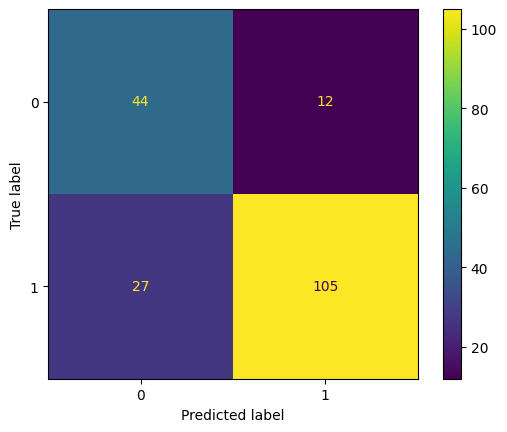

In [137]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_tuned)).plot();

RandomForest

In [138]:
rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# оценка при стандартном пороге
y_pred = rf_model.predict(X_test)
print("=== Random Forest (default threshold) ===")
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("Business metric:", credit_gain_score(y_test, y_pred))

=== Random Forest (default threshold) ===
Precision: 0.8243243243243243
Recall: 0.9242424242424242
Business metric: -62


In [139]:
# подбор оптимального порога
tuned_rf = TunedThresholdClassifierCV(
    estimator=rf_model,
    scoring=scoring,
    thresholds=100
)

tuned_rf.fit(X_train, y_train)

print(f"Best threshold (RF): {tuned_rf.best_threshold_:.3f}")


Best threshold (RF): 0.659


In [140]:
# оценка после подбора порога
y_pred_tuned = tuned_rf.predict(X_test)

print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall:", recall_score(y_test, y_pred_tuned))
print("Business metric:", credit_gain_score(y_test, y_pred_tuned))

Precision: 0.875
Recall: 0.7954545454545454
Business metric: -57


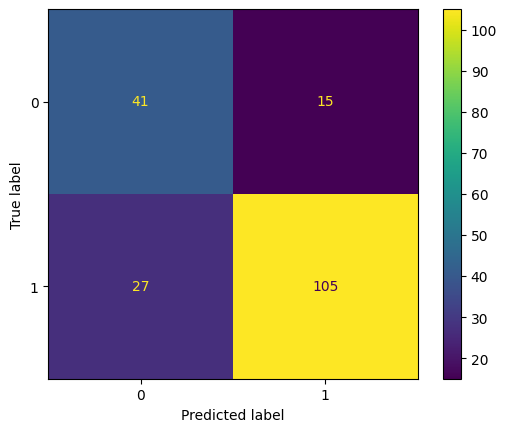

In [141]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_tuned)).plot();

SVC

In [142]:
svc_model = make_pipeline(
    StandardScaler(),
    SVC(probability=True)
)

svc_model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(probability=True))])

In [143]:
# оценка при стандартном пороге
y_pred = svc_model.predict(X_test)

print("=== SVC (default threshold) ===")
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("Business metric:", credit_gain_score(y_test, y_pred))

=== SVC (default threshold) ===
Precision: 0.7875
Recall: 0.9545454545454546
Business metric: -74


In [144]:
# подбор оптимального порога
tuned_svc = TunedThresholdClassifierCV(
    estimator=svc_model,
    scoring=scoring,
    thresholds=100
)

tuned_svc.fit(X_train, y_train)

print(f"Best threshold (SVC): {tuned_svc.best_threshold_:.3f}")

Best threshold (SVC): 0.741


In [145]:
# оценка после подбора порога
y_pred_tuned = tuned_svc.predict(X_test)

print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall:", recall_score(y_test, y_pred_tuned))
print("Business metric:", credit_gain_score(y_test, y_pred_tuned))

Precision: 0.875
Recall: 0.6893939393939394
Business metric: -67


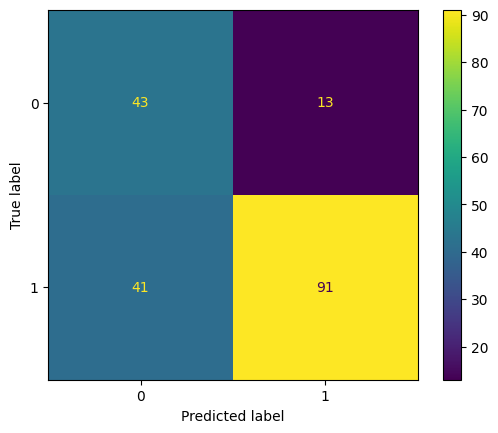

In [146]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_tuned)).plot();

In [147]:
results = {
    "Logistic": {
        "threshold": tuned_logistic.best_threshold_,
        "precision": precision_score(y_test, tuned_logistic.predict(X_test)),
        "recall": recall_score(y_test, tuned_logistic.predict(X_test)),
        "business": credit_gain_score(y_test, tuned_logistic.predict(X_test))
    },
    "RandomForest": {
        "threshold": tuned_rf.best_threshold_,
        "precision": precision_score(y_test, tuned_rf.predict(X_test)),
        "recall": recall_score(y_test, tuned_rf.predict(X_test)),
        "business": credit_gain_score(y_test, tuned_rf.predict(X_test))
    },
    "SVC": {
        "threshold": tuned_svc.best_threshold_,
        "precision": precision_score(y_test, tuned_svc.predict(X_test)),
        "recall": recall_score(y_test, tuned_svc.predict(X_test)),
        "business": credit_gain_score(y_test, tuned_svc.predict(X_test))
    }
}

results_df = pd.DataFrame(results).T
results_df


,threshold,precision,recall,business
Logistic,0.699476,0.897436,0.795455,-51.0
RandomForest,0.658667,0.875000,0.795455,-57.0
SVC,0.740595,0.875000,0.689394,-67.0


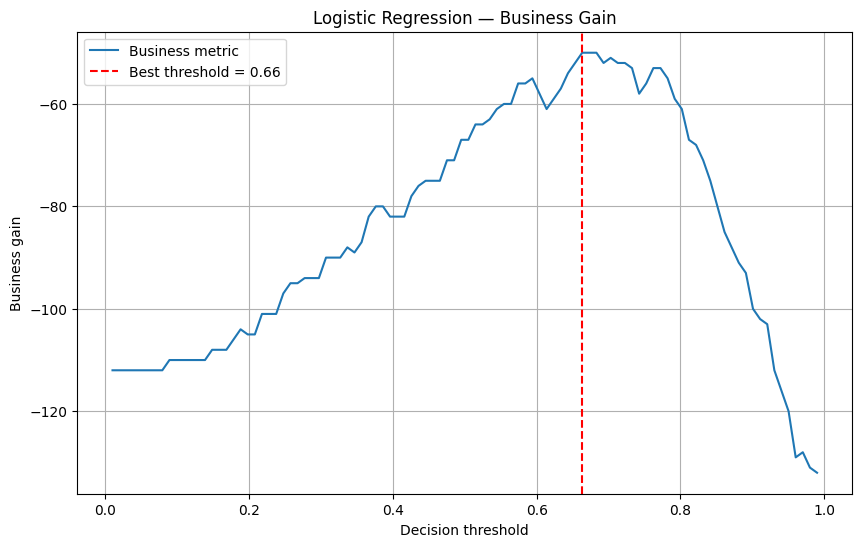

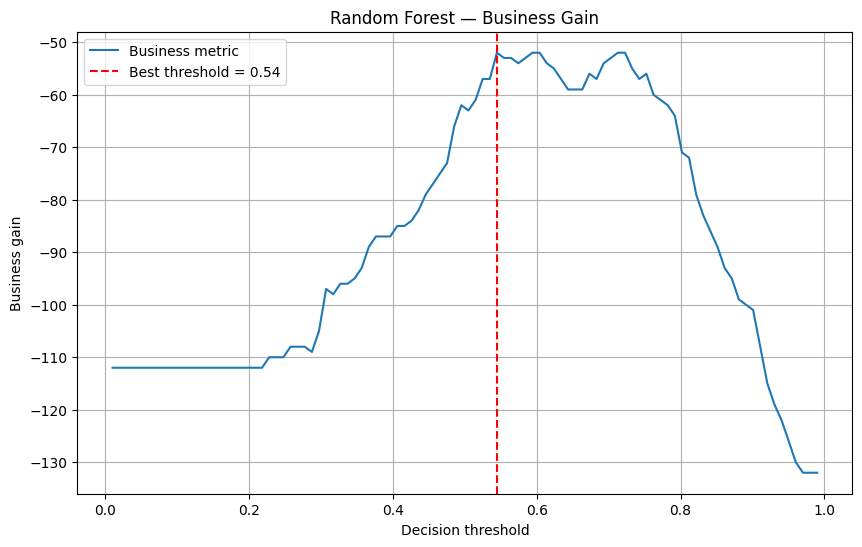

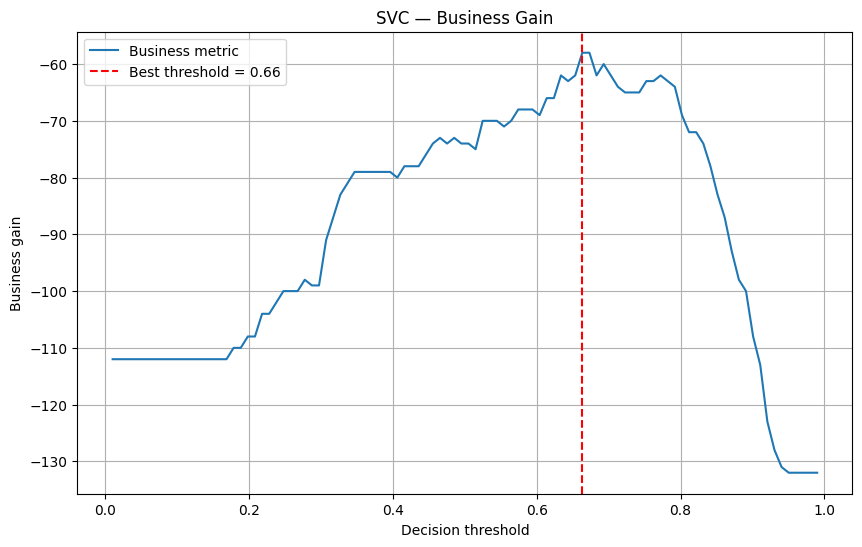

In [148]:
def plot_business_curve(model, X, y, title):
    thresholds = np.linspace(0.01, 0.99, 100)
    scores = []

    probs = model.predict_proba(X)[:, 1]

    for t in thresholds:
        y_pred = (probs >= t).astype(int)
        scores.append(credit_gain_score(y, y_pred))

    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, scores, label="Business metric")
    plt.axvline(thresholds[np.argmax(scores)], linestyle="--", color="red",
                label=f"Best threshold = {thresholds[np.argmax(scores)]:.2f}")
    plt.xlabel("Decision threshold")
    plt.ylabel("Business gain")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

plot_business_curve(tuned_logistic, X_test, y_test, "Logistic Regression — Business Gain")
plot_business_curve(tuned_rf, X_test, y_test, "Random Forest — Business Gain")
plot_business_curve(tuned_svc, X_test, y_test, "SVC — Business Gain")

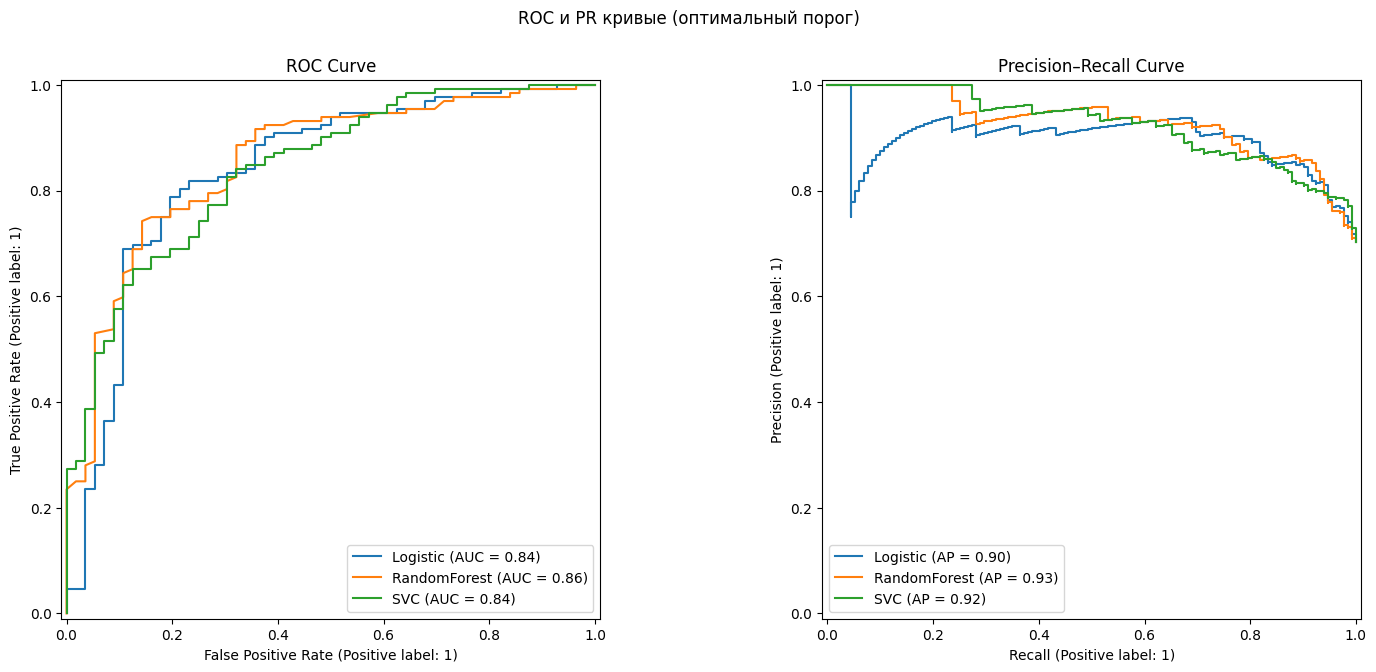

In [149]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

def plot_roc_pr(models, X_test, y_test, title):
    fig, axs = plt.subplots(1, 2, figsize=(18, 7))

    for name, model in models.items():
        # ROC
        RocCurveDisplay.from_estimator(
            model,
            X_test,
            y_test,
            ax=axs[0],
            name=name
        )

        # PR
        PrecisionRecallDisplay.from_estimator(
            model,
            X_test,
            y_test,
            ax=axs[1],
            name=name
        )

    axs[0].set_title("ROC Curve")
    axs[1].set_title("Precision–Recall Curve")
    plt.suptitle(title)
    plt.show()

plot_roc_pr(
    models={
        "Logistic": tuned_logistic,
        "RandomForest": tuned_rf,
        "SVC": tuned_svc
    },
    X_test=X_test,
    y_test=y_test,
    title="ROC и PR кривые (оптимальный порог)"
)